<a href="https://colab.research.google.com/github/sreejoyee-debug/Introduction-to-AI/blob/main/Applying_six_ML_models_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
!pip install imbalanced-learn -q

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import RandomOverSampler

import warnings
warnings.filterwarnings("ignore")

In [23]:
uploaded = files.upload()

Saving stroke_processed_5k.csv to stroke_processed_5k (1).csv


In [24]:
df = pd.read_csv("stroke_processed_5k.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5110, 11)

First 5 rows:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1



Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB

Missing Values:
gender   

In [25]:
# Target variable
target = "stroke"

# Features
X = df.drop(columns=[target])

# Target
y = df[target]

print("Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Features:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']

Target Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64

Target Percentage:
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4088, 10)
Testing data: (1022, 10)


In [27]:
# Keep the original imbalanced training data unchanged.
X_train_original = X_train.copy()
y_train_original = y_train.copy()

print("Original imbalanced training data preserved!")
print("\nOriginal training class distribution:")
print(y_train_original.value_counts())

Original imbalanced training data preserved!

Original training class distribution:
stroke
0    3889
1     199
Name: count, dtype: int64


In [28]:
from imblearn.ensemble import BalancedBaggingClassifier

def create_models():

    models = {

        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ]),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=6,
            class_weight="balanced",
            random_state=42
        ),

        "Random Forest": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=RandomForestClassifier(
                    n_estimators=300,
                    random_state=42,
                    n_jobs=-1
                ),
                sampling_strategy="auto",
                replacement=False,
                random_state=42
            ))
        ]),

        "SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=42
            ))
        ]),

        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=KNeighborsClassifier(n_neighbors=7),
                sampling_strategy="auto",
                replacement=False,
                random_state=42
            ))
        ]),

        "ANN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", BalancedBaggingClassifier(
                estimator=MLPClassifier(
                    hidden_layer_sizes=(64, 32),
                    activation="relu",
                    solver="adam",
                    max_iter=500,
                    early_stopping=True,
                    random_state=42
                ),
                sampling_strategy="auto",
                replacement=False,
                random_state=42
            ))
        ])
    }

    return models

models = create_models()
print("Six models created with the same configurations as the original-imbalanced experiment.")

Six models created with the same configurations as the original-imbalanced experiment.


In [29]:
results = []
trained_models = {}
confusion_matrices = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train on the original imbalanced training data (no oversampling or SMOTE).
    model.fit(X_train_original, y_train_original)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    confusion_matrices[name] = cm

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC-ROC": auc
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))
    print("AUC-ROC:", round(auc, 4))

print("\nAll six models trained and evaluated on the original imbalanced data.")




Training: Logistic Regression
Accuracy: 0.7515
Precision: 0.1408
Recall: 0.8
F1-Score: 0.2395
AUC-ROC: 0.8387

Training: Decision Tree
Accuracy: 0.7456
Precision: 0.114
Recall: 0.62
F1-Score: 0.1925
AUC-ROC: 0.7183

Training: Random Forest
Accuracy: 0.7554
Precision: 0.1429
Recall: 0.8
F1-Score: 0.2424
AUC-ROC: 0.8237

Training: SVM
Accuracy: 0.7358
Precision: 0.1181
Recall: 0.68
F1-Score: 0.2012
AUC-ROC: 0.7856

Training: KNN
Accuracy: 0.6996
Precision: 0.1164
Recall: 0.78
F1-Score: 0.2026
AUC-ROC: 0.798

Training: ANN
Accuracy: 0.6947
Precision: 0.1124
Recall: 0.76
F1-Score: 0.1959
AUC-ROC: 0.8239

All six models trained and evaluated on the original imbalanced data.


In [30]:
results_df = pd.DataFrame(results)

# Sort all models according to F1-Score
results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON - ORIGINAL IMBALANCED DATA")
print("=" * 80)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "AUC-ROC": "{:.4f}"
    })
)

MODEL PERFORMANCE COMPARISON - ORIGINAL IMBALANCED DATA


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Random Forest,0.7554,0.1429,0.8000,0.2424,0.8237
1,Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8387
2,KNN,0.6996,0.1164,0.7800,0.2026,0.7980
3,SVM,0.7358,0.1181,0.6800,0.2012,0.7856
4,ANN,0.6947,0.1124,0.7600,0.1959,0.8239
5,Decision Tree,0.7456,0.1140,0.6200,0.1925,0.7183


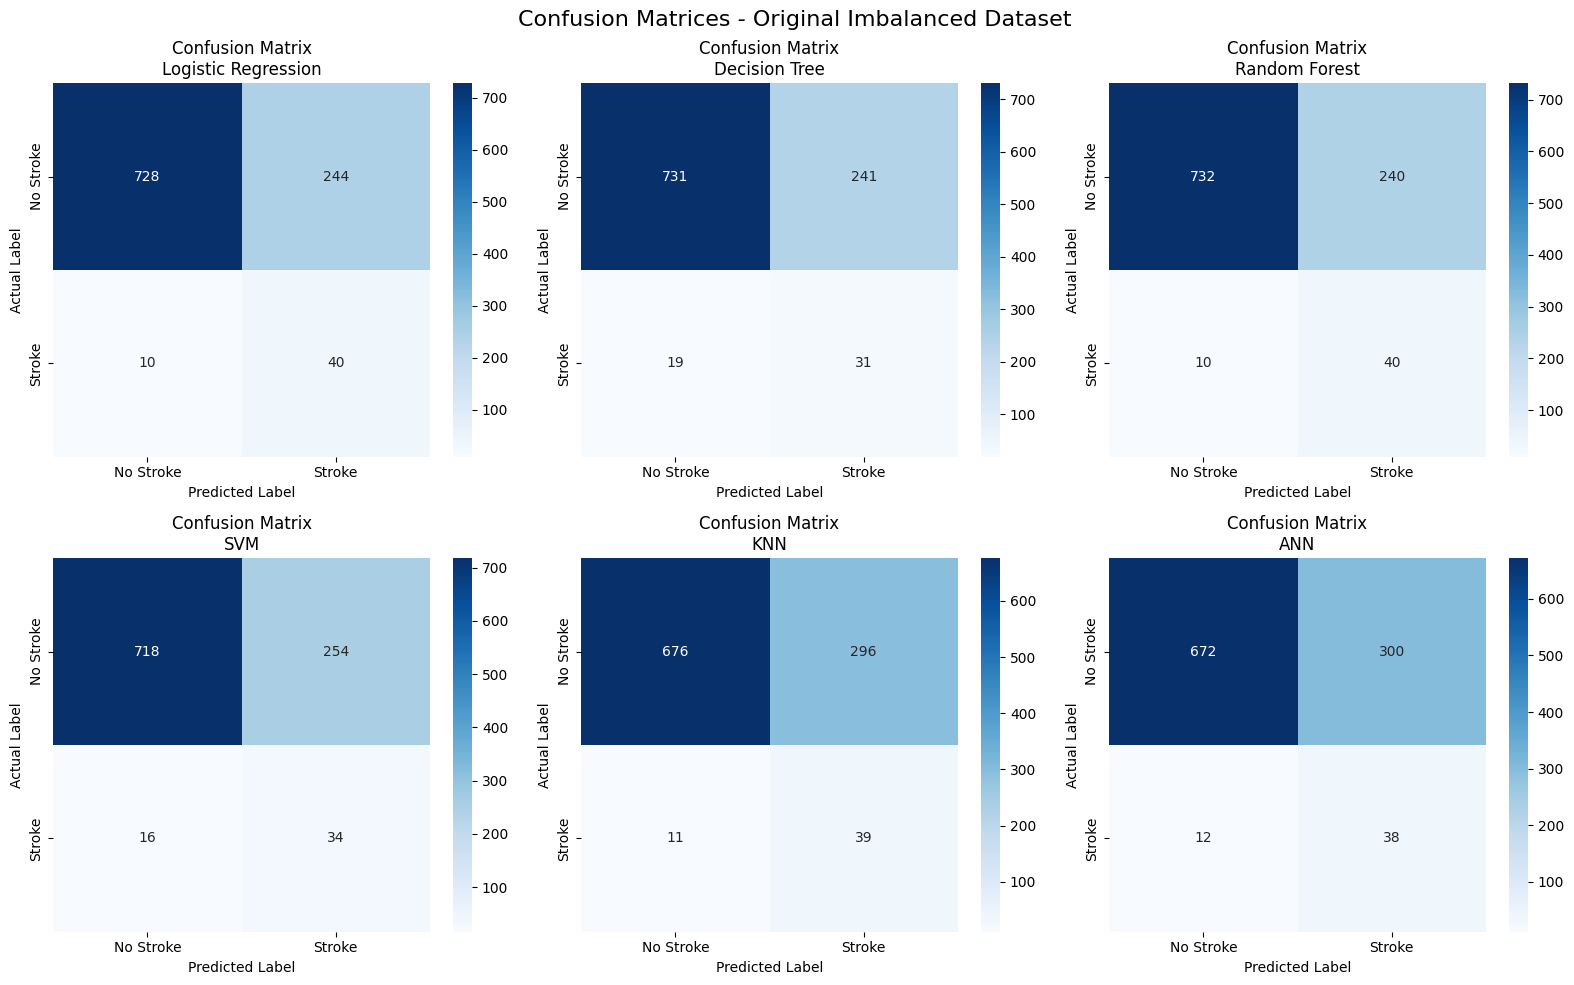

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, (name, cm) in enumerate(confusion_matrices.items()):
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["No Stroke", "Stroke"],
        yticklabels=["No Stroke", "Stroke"]
    )
    axes[i].set_title(f"Confusion Matrix\n{name}")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle("Confusion Matrices - Original Imbalanced Dataset", fontsize=16)
plt.tight_layout()
plt.show()

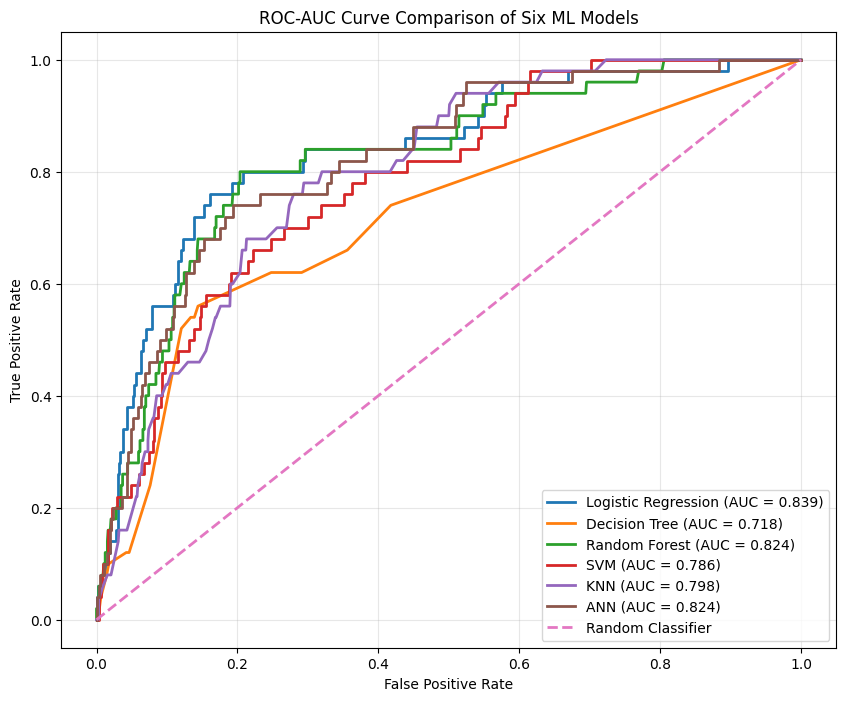

In [32]:
plt.figure(figsize=(10, 8))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC-AUC Curve Comparison of Six ML Models"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.show()

In [33]:
for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Stroke", "Stroke"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.95      0.75      0.82      1022


Decision Tree
              precision    recall  f1-score   support

   No Stroke       0.97      0.75      0.85       972
      Stroke       0.11      0.62      0.19        50

    accuracy                           0.75      1022
   macro avg       0.54      0.69      0.52      1022
weighted avg       0.93      0.75      0.82      1022


Random Forest
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.78      0.55      1022
weighted avg       0.95

In [34]:
# Select Top 3 models based on F1-Score
top_3 = results_df.head(3)

print("TOP 3 MODELS FOR STROKE RISK PREDICTION")
print("=" * 60)

display(
    top_3.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "AUC-ROC": "{:.4f}"
    })
)

TOP 3 MODELS FOR STROKE RISK PREDICTION


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Random Forest,0.7554,0.1429,0.8000,0.2424,0.8237
1,Logistic Regression,0.7515,0.1408,0.8000,0.2395,0.8387
2,KNN,0.6996,0.1164,0.7800,0.2026,0.7980


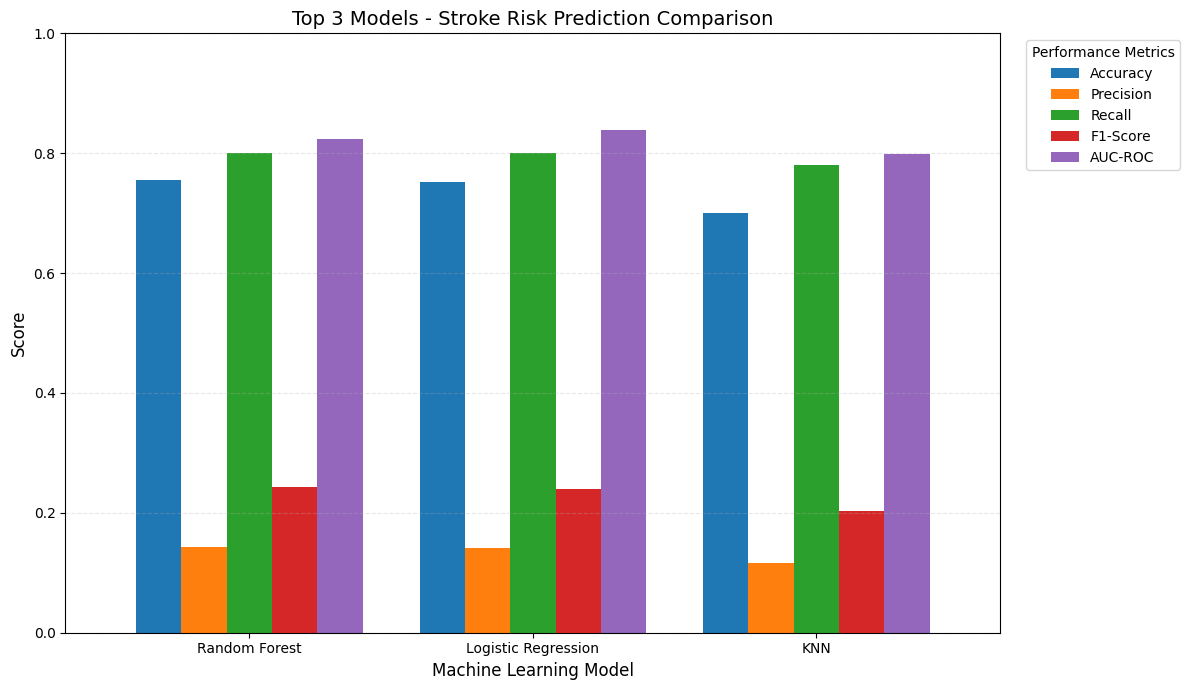

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "AUC-ROC"
]

# Define top_3 directly from results_df to ensure it exists
top_3 = results_df.head(3)

# Select the top 3 models and their performance metrics
top3_plot = top_3.set_index("Model")[metrics]

# Create the bar chart
ax = top3_plot.plot(
    kind="bar",
    figsize=(12, 7),
    width=0.8
)

# Customize the chart
plt.title("Top 3 Models - Stroke Risk Prediction Comparison", fontsize=14)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.legend(
    title="Performance Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

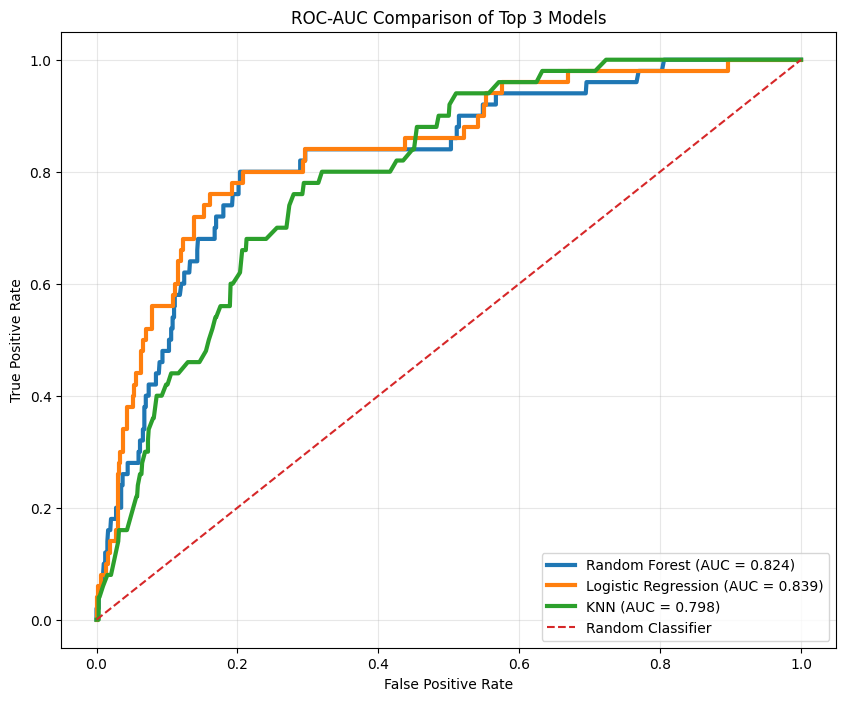

In [36]:
plt.figure(figsize=(10, 8))

for name in top_3["Model"]:

    model = trained_models[name]

    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=3,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "ROC-AUC Comparison of Top 3 Models"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.show()

In [37]:
print("="*75)
print("FINAL STROKE RISK PREDICTION ANALYSIS")
print("="*75)

for i, row in top_3.reset_index(drop=True).iterrows():

    print(f"\n{i+1}. {row['Model']}")

    print(f"   Accuracy  : {row['Accuracy']:.4f}")

    print(f"   Precision : {row['Precision']:.4f}")

    print(f"   Recall    : {row['Recall']:.4f}")

    print(f"   F1-Score  : {row['F1-Score']:.4f}")

    print(f"   AUC-ROC   : {row['AUC-ROC']:.4f}")


print("\n" + "="*75)

best_f1_model = top_3.iloc[0]["Model"]

print(
    f"\nBased on F1-Score, the top model is: {best_f1_model}"
)

print(
    "\nThe models were evaluated using Accuracy, Precision, "
    "Recall, F1-Score, AUC-ROC and Confusion Matrix."
)

print(
    "\nFor stroke-risk analysis, Recall and F1-Score are particularly "
    "important because missing an actual stroke case is undesirable."
)

FINAL STROKE RISK PREDICTION ANALYSIS

1. Random Forest
   Accuracy  : 0.7554
   Precision : 0.1429
   Recall    : 0.8000
   F1-Score  : 0.2424
   AUC-ROC   : 0.8237

2. Logistic Regression
   Accuracy  : 0.7515
   Precision : 0.1408
   Recall    : 0.8000
   F1-Score  : 0.2395
   AUC-ROC   : 0.8387

3. KNN
   Accuracy  : 0.6996
   Precision : 0.1164
   Recall    : 0.7800
   F1-Score  : 0.2026
   AUC-ROC   : 0.7980


Based on F1-Score, the top model is: Random Forest

The models were evaluated using Accuracy, Precision, Recall, F1-Score, AUC-ROC and Confusion Matrix.

For stroke-risk analysis, Recall and F1-Score are particularly important because missing an actual stroke case is undesirable.
